In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ta.momentum import RSIIndicator
from ta.trend import EMAIndicator, MACD
from ta.volatility import AverageTrueRange
import itertools
import warnings
warnings.filterwarnings("ignore")

In [57]:
path = "/Users/mac/Desktop/Upwork/GoldSignalGenerator/Artifacts/gold.csv"
df = pd.read_csv(path, skiprows=[1])
df.head()

,Price,Close,High,Low,Open,Volume
0,Datetime,NaN,NaN,NaN,NaN,NaN
1,2023-05-11 00:00:00,2037.099976,2038.599976,2036.199951,2038.599976,0.0
2,2023-05-11 01:00:00,2038.400024,2039.199951,2036.099976,2037.099976,2132.0
3,2023-05-11 02:00:00,2033.500000,2038.900024,2033.300049,2038.300049,6292.0
4,2023-05-11 03:00:00,2031.599976,2034.500000,2027.599976,2033.500000,10998.0


In [58]:
df.index = pd.to_datetime(df.index, utc=True).map(lambda x: x.tz_convert('Asia/Karachi'))
df = df.drop(df.index[0])
df = df.reset_index(drop=True)
df.rename(columns={"Price" : "Datetime"}, inplace=True)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df.head()

,Datetime,Close,High,Low,Open,Volume
0,2023-05-11 00:00:00,2037.099976,2038.599976,2036.199951,2038.599976,0.0
1,2023-05-11 01:00:00,2038.400024,2039.199951,2036.099976,2037.099976,2132.0
2,2023-05-11 02:00:00,2033.500000,2038.900024,2033.300049,2038.300049,6292.0
3,2023-05-11 03:00:00,2031.599976,2034.500000,2027.599976,2033.500000,10998.0
4,2023-05-11 04:00:00,2028.400024,2031.500000,2027.599976,2031.500000,7245.0


In [59]:
df.tail()

,Datetime,Close,High,Low,Open,Volume
13762,2025-10-01 12:00:00,3897.600098,3898.199951,3887.300049,3895.000000,10920.0
13763,2025-10-01 13:00:00,3887.399902,3898.500000,3887.300049,3897.699951,9975.0
13764,2025-10-01 14:00:00,3888.699951,3893.100098,3881.399902,3887.600098,11591.0
13765,2025-10-01 15:00:00,3894.300049,3897.600098,3887.800049,3888.800049,7184.0
13766,2025-10-01 16:00:00,3894.300049,3894.399902,3893.199951,3894.300049,152.0


In [61]:
type(df["Datetime"])

pandas.core.series.Series

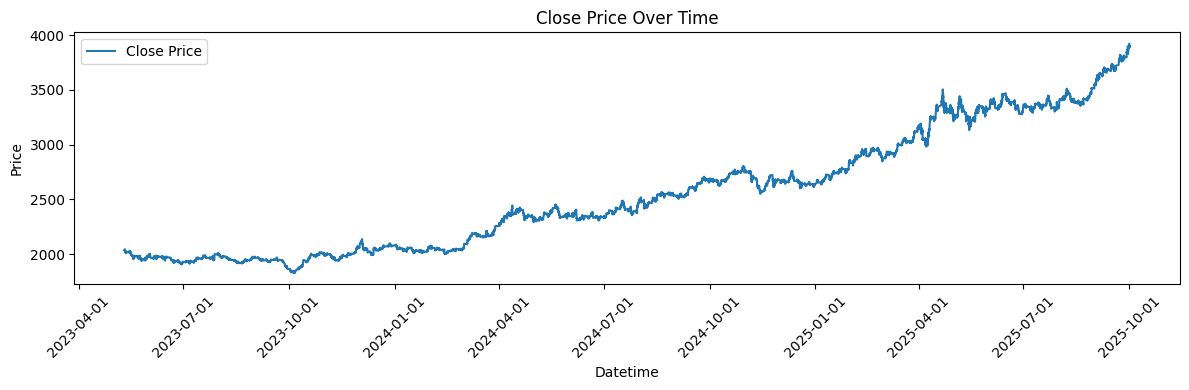

Rows: 13767
Nulls per column:
 Datetime    0
Close       0
High        0
Low         0
Open        0
Volume      0
dtype: int64


In [62]:
import matplotlib.dates as mdates

plt.figure(figsize=(12, 4))
plt.plot(df['Datetime'], df['Close'], label="Close Price")

plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())   
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))

plt.xticks(rotation=45)  
plt.title("Close Price Over Time")
plt.xlabel("Datetime")
plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()

print("Rows:", len(df))
print("Nulls per column:\n", df.isna().sum())


In [63]:
df = df.copy()
df['Close'] = df['Close'].ffill()
df['High'] = df['High'].ffill()
df['Low']  = df['Low'].ffill()

# Returns
df['return'] = df['Close'].pct_change()

# EMAs
df['ema_fast'] = EMAIndicator(df['Close'], window=12).ema_indicator()
df['ema_slow'] = EMAIndicator(df['Close'], window=26).ema_indicator()

# RSI
df['rsi'] = RSIIndicator(df['Close'], window=14).rsi()

# MACD
macd = MACD(df['Close'])
df['macd'] = macd.macd()
df['macd_signal'] = macd.macd_signal()

# ATR (volatility) — important for SL/TP sizing
df['ATR'] = AverageTrueRange(df['High'], df['Low'], df['Close'], window=14).average_true_range()

# Drop initial rows where ATR is NaN (these rows cannot trade sensibly)
df = df.dropna(subset=['ATR']).reset_index(drop=True)

df[['Datetime','Close','ATR','rsi','ema_fast','ema_slow']].head(30)

,Datetime,Close,ATR,rsi,ema_fast,ema_slow
0,2023-05-11 00:00:00,2037.099976,0.000000,NaN,NaN,NaN
1,2023-05-11 01:00:00,2038.400024,0.000000,NaN,NaN,NaN
2,2023-05-11 02:00:00,2033.500000,0.000000,NaN,NaN,NaN
3,2023-05-11 03:00:00,2031.599976,0.000000,NaN,NaN,NaN
4,2023-05-11 04:00:00,2028.400024,0.000000,NaN,NaN,NaN
5,2023-05-11 05:00:00,2032.699951,0.000000,NaN,NaN,NaN
6,2023-05-11 06:00:00,2035.000000,0.000000,NaN,NaN,NaN
7,2023-05-11 07:00:00,2043.000000,0.000000,NaN,NaN,NaN
8,2023-05-11 08:00:00,2043.500000,0.000000,NaN,NaN,NaN
9,2023-05-11 09:00:00,2018.400024,0.000000,NaN,NaN,NaN


In [64]:
def make_labels(df, horizon=6, threshold=0.003):
    df = df.copy().reset_index(drop=True)
    df['future_return'] = (df['Close'].shift(-horizon) - df['Close']) / df['Close']
    def label_signal(x):
        if pd.isna(x): 
            return 0
        if x > threshold:
            return 1  # Buy
        elif x < -threshold:
            return 2  # Sell
        else:
            return 0  # Hold
    df['signal'] = df['future_return'].apply(label_signal)
    return df


In [65]:
def backtest_strategy(df, horizon=6, threshold=0.003, rr_ratio=2.0, risk_mult=1.0, verbose=True):

    df = df.copy().reset_index(drop=True)

    if 'ATR' not in df.columns:
        df['ATR'] = AverageTrueRange(df['High'], df['Low'], df['Close'], window=14).average_true_range()

    df = make_labels(df, horizon=horizon, threshold=threshold)

    df['Entry'] = df['Close']
    df['StopLoss'] = np.where(
        df['signal'] == 1, df['Entry'] - risk_mult * df['ATR'],
        np.where(df['signal'] == 2, df['Entry'] + risk_mult * df['ATR'], np.nan)
    )
    df['TakeProfit'] = np.where(
        df['signal'] == 1, df['Entry'] + rr_ratio * risk_mult * df['ATR'],
        np.where(df['signal'] == 2, df['Entry'] - rr_ratio * risk_mult * df['ATR'], np.nan)
    )

    trade_records = []
    trade_result_series = np.zeros(len(df), dtype=int)  
    pnl_price_series = np.zeros(len(df), dtype=float)   
    pnl_atr_series = np.zeros(len(df), dtype=float)     

    for i in range(len(df) - horizon):
        sig = int(df.loc[i, 'signal'])
        if sig == 0:
            continue

        entry_price = df.loc[i, 'Entry']
        atr_entry   = df.loc[i, 'ATR']
        sl = df.loc[i, 'StopLoss']
        tp = df.loc[i, 'TakeProfit']

        future = df.loc[i+1 : i+horizon].copy()
        if future.empty:
            continue

        if sig == 1: 
            tp_hits = future[future['High'] >= tp]
            sl_hits = future[future['Low'] <= sl]
            tp_idx = tp_hits.index.tolist()
            sl_idx = sl_hits.index.tolist()
            if tp_idx and not sl_idx:
                exit_idx = tp_idx[0]; result = 1; exit_price = tp
            elif sl_idx and not tp_idx:
                exit_idx = sl_idx[0]; result = -1; exit_price = sl
            elif tp_idx and sl_idx:

                if tp_idx[0] < sl_idx[0]:
                    exit_idx = tp_idx[0]; result = 1; exit_price = tp
                else:
                    exit_idx = sl_idx[0]; result = -1; exit_price = sl
            else:
                exit_idx = None; result = 0; exit_price = np.nan

        else:  
            tp_hits = future[future['Low'] <= tp]
            sl_hits = future[future['High'] >= sl]
            tp_idx = tp_hits.index.tolist()
            sl_idx = sl_hits.index.tolist()
            if tp_idx and not sl_idx:
                exit_idx = tp_idx[0]; result = 1; exit_price = tp
            elif sl_idx and not tp_idx:
                exit_idx = sl_idx[0]; result = -1; exit_price = sl
            elif tp_idx and sl_idx:
                if tp_idx[0] < sl_idx[0]:
                    exit_idx = tp_idx[0]; result = 1; exit_price = tp
                else:
                    exit_idx = sl_idx[0]; result = -1; exit_price = sl
            else:
                exit_idx = None; result = 0; exit_price = np.nan

        if result != 0:
            trade_result_series[i] = result
            if sig == 1:  # buy
                pnl_price = exit_price - entry_price
            else:  # sell
                pnl_price = entry_price - exit_price

            pnl_atr = pnl_price / atr_entry if atr_entry != 0 else 0.0

            pnl_price_series[i] = pnl_price
            pnl_atr_series[i] = pnl_atr

            record = {
                'entry_idx': i,
                'entry_time': df.loc[i,'Datetime'],
                'signal': 'BUY' if sig==1 else 'SELL',
                'entry_price': entry_price,
                'atr_entry': atr_entry,
                'stop_loss': sl,
                'take_profit': tp,
                'exit_idx': int(exit_idx) if exit_idx is not None else np.nan,
                'exit_time': df.loc[int(exit_idx),'Datetime'] if exit_idx is not None else pd.NaT,
                'exit_price': exit_price,
                'result': int(result),  # 1 win, -1 loss
                'pnl_price': pnl_price,
                'pnl_atr': pnl_atr
            }
            trade_records.append(record)

    trades_df = pd.DataFrame(trade_records)

    df['trade_result'] = trade_result_series
    df['pnl_price'] = pnl_price_series
    df['pnl_atr'] = pnl_atr_series
    df['equity_price'] = df['pnl_price'].cumsum()
    df['equity_atr'] = df['pnl_atr'].cumsum()

    # Metrics
    total_trades = len(trades_df)
    wins = trades_df[trades_df['result'] == 1].shape[0]
    losses = trades_df[trades_df['result'] == -1].shape[0]
    win_rate = wins / total_trades * 100 if total_trades > 0 else 0.0

    total_profit = trades_df.loc[trades_df['pnl_price'] > 0, 'pnl_price'].sum()
    total_loss = trades_df.loc[trades_df['pnl_price'] < 0, 'pnl_price'].sum()
    profit_factor = total_profit / abs(total_loss) if total_loss != 0 else np.inf

    avg_win = trades_df.loc[trades_df['pnl_price'] > 0, 'pnl_price'].mean() if wins>0 else 0.0
    avg_loss = abs(trades_df.loc[trades_df['pnl_price'] < 0, 'pnl_price'].mean()) if losses>0 else 0.0

    metrics = {
        'total_trades': total_trades,
        'wins': wins,
        'losses': losses,
        'win_rate_pct': win_rate,
        'total_profit': total_profit,
        'total_loss': total_loss,
        'profit_factor': profit_factor,
        'avg_win': avg_win,
        'avg_loss': avg_loss
    }

    if verbose:
        print("📊 Strategy Report")
        print(f"Total Trades: {total_trades}")
        print(f"Wins: {wins}, Losses: {losses}, Win Rate: {win_rate:.2f}%")
        print(f"Profit Factor: {profit_factor:.2f}")
        print(f"Avg Win: {avg_win:.4f}, Avg Loss: {avg_loss:.4f}")

    return df, trades_df, metrics


In [67]:
enriched, trades, metrics = backtest_strategy(df, horizon=6, threshold=0.01, rr_ratio=2, verbose=True)

print("\nMetrics dict:", metrics)
print("\nTrade-level sample:")


📊 Strategy Report
Total Trades: 697
Wins: 575, Losses: 122, Win Rate: 82.50%
Profit Factor: 9.09
Avg Win: 22.4414, Avg Loss: 11.8355

Metrics dict: {'total_trades': 697, 'wins': 575, 'losses': 122, 'win_rate_pct': 82.49641319942612, 'total_profit': np.float64(12903.786779267662), 'total_loss': np.float64(-1420.2630875886186), 'profit_factor': np.float64(9.085490492593344), 'avg_win': np.float64(22.441368311769846), 'avg_loss': np.float64(11.835525729905156)}

Trade-level sample:


In [27]:
def optimize_strategy(df, horizons=[6,12,24], thresholds=[0.003,0.005,0.01], rr_ratios=[2,3]):
    results = []
    for h, t, rr in itertools.product(horizons, thresholds, rr_ratios):
        print(f"Testing Horizon={h}, Threshold={t}, RR={rr}...")
        enriched, trades_df, metrics = backtest_strategy(df, horizon=h, threshold=t, rr_ratio=rr, verbose=False)
        # store metrics in consistent, human-readable format
        results.append({
            'horizon': h,
            'threshold': t,
            'rr_ratio': rr,
            'total_trades': metrics['total_trades'],
            'win_rate_pct': metrics['win_rate_pct'],
            'profit_factor': metrics['profit_factor'],
            'avg_win': metrics['avg_win'],
            'avg_loss': metrics['avg_loss']
        })
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values(by='profit_factor', ascending=False).reset_index(drop=True)
    return results_df


grid_results = optimize_strategy(df, horizons=[6,12,24], thresholds=[0.003,0.005,0.01], rr_ratios=[2,3])
grid_results


Testing Horizon=6, Threshold=0.003, RR=2...
Testing Horizon=6, Threshold=0.003, RR=3...
Testing Horizon=6, Threshold=0.005, RR=2...
Testing Horizon=6, Threshold=0.005, RR=3...
Testing Horizon=6, Threshold=0.01, RR=2...
Testing Horizon=6, Threshold=0.01, RR=3...
Testing Horizon=12, Threshold=0.003, RR=2...
Testing Horizon=12, Threshold=0.003, RR=3...
Testing Horizon=12, Threshold=0.005, RR=2...
Testing Horizon=12, Threshold=0.005, RR=3...
Testing Horizon=12, Threshold=0.01, RR=2...
Testing Horizon=12, Threshold=0.01, RR=3...
Testing Horizon=24, Threshold=0.003, RR=2...
Testing Horizon=24, Threshold=0.003, RR=3...
Testing Horizon=24, Threshold=0.005, RR=2...
Testing Horizon=24, Threshold=0.005, RR=3...
Testing Horizon=24, Threshold=0.01, RR=2...
Testing Horizon=24, Threshold=0.01, RR=3...


,horizon,threshold,rr_ratio,total_trades,win_rate_pct,profit_factor,avg_win,avg_loss
0,6,0.010,3,618,80.258900,9.687728,27.740167,11.835526
1,6,0.010,2,697,82.496413,9.085490,22.441368,11.835526
2,12,0.010,3,1613,72.225666,5.784337,27.970479,12.630991
3,6,0.005,2,2567,79.041683,5.618926,17.734424,11.986447
4,12,0.010,2,1729,74.378253,4.950882,21.582140,12.712012
5,6,0.005,3,1903,71.571203,4.713762,22.243215,11.959520
6,6,0.003,2,4116,75.340136,4.105358,16.006523,11.978889
7,12,0.005,3,4063,64.484371,3.894053,23.153246,10.851595
8,12,0.005,2,4770,70.398323,3.867168,17.732669,10.963904
9,24,0.010,3,3619,61.011329,3.518043,26.619062,11.890891


In [28]:
print(grid_results.head)

<bound method NDFrame.head of     horizon  threshold  rr_ratio  total_trades  win_rate_pct  profit_factor  \
0         6      0.010         3           618     80.258900       9.687728   
1         6      0.010         2           697     82.496413       9.085490   
2        12      0.010         3          1613     72.225666       5.784337   
3         6      0.005         2          2567     79.041683       5.618926   
4        12      0.010         2          1729     74.378253       4.950882   
5         6      0.005         3          1903     71.571203       4.713762   
6         6      0.003         2          4116     75.340136       4.105358   
7        12      0.005         3          4063     64.484371       3.894053   
8        12      0.005         2          4770     70.398323       3.867168   
9        24      0.010         3          3619     61.011329       3.518043   
10       12      0.003         2          6866     66.545296       3.129614   
11       24      0.005

In [30]:
display(grid_results)

# Pick best by profit_factor
best = grid_results.iloc[0]
print("Best combination (by profit_factor):")
print(best)

# Run best to plot equity & trades
best_enriched, best_trades, best_metrics = backtest_strategy(df,
                                                            horizon=int(best.horizon),
                                                            threshold=float(best.threshold),
                                                            rr_ratio=float(best.rr_ratio),
                                                            verbose=True)


,horizon,threshold,rr_ratio,total_trades,win_rate_pct,profit_factor,avg_win,avg_loss
0,6,0.010,3,618,80.258900,9.687728,27.740167,11.835526
1,6,0.010,2,697,82.496413,9.085490,22.441368,11.835526
2,12,0.010,3,1613,72.225666,5.784337,27.970479,12.630991
3,6,0.005,2,2567,79.041683,5.618926,17.734424,11.986447
4,12,0.010,2,1729,74.378253,4.950882,21.582140,12.712012
5,6,0.005,3,1903,71.571203,4.713762,22.243215,11.959520
6,6,0.003,2,4116,75.340136,4.105358,16.006523,11.978889
7,12,0.005,3,4063,64.484371,3.894053,23.153246,10.851595
8,12,0.005,2,4770,70.398323,3.867168,17.732669,10.963904
9,24,0.010,3,3619,61.011329,3.518043,26.619062,11.890891


Best combination (by profit_factor):
horizon            6.000000
threshold          0.010000
rr_ratio           3.000000
total_trades     618.000000
win_rate_pct      80.258900
profit_factor      9.687728
avg_win           27.740167
avg_loss          11.835526
Name: 0, dtype: float64
📊 Strategy Report
Total Trades: 618
Wins: 496, Losses: 122, Win Rate: 80.26%
Profit Factor: 9.69
Avg Win: 27.7402, Avg Loss: 11.8355


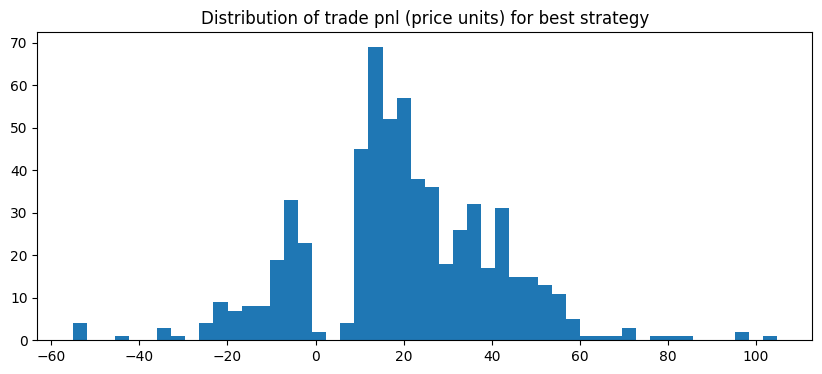

Wins / Losses count: 496 122
Win rate (%) 80.2588996763754
Profit Factor 9.687728088462645
Avg Win / Avg Loss (price units): 27.740166545643028 11.835525729905156


In [31]:
if not best_trades.empty:
    plt.figure(figsize=(10,4))
    plt.hist(best_trades['pnl_price'], bins=50)
    plt.title("Distribution of trade pnl (price units) for best strategy")
    plt.show()

    print("Wins / Losses count:", best_metrics['wins'], best_metrics['losses'])
    print("Win rate (%)", best_metrics['win_rate_pct'])
    print("Profit Factor", best_metrics['profit_factor'])
    print("Avg Win / Avg Loss (price units):", best_metrics['avg_win'], best_metrics['avg_loss'])
else:
    print("No trades for best strategy — inspect parameters.")


### Feature Engineering

In [34]:
from ta.momentum import StochasticOscillator, ROCIndicator
from ta.trend import SMAIndicator
from ta.volatility import BollingerBands

# --- Momentum ---
df['stoch_k'] = StochasticOscillator(df['Close'], df['High'], df['Low']).stoch()
df['roc'] = ROCIndicator(df['Close'], window=12).roc()

# --- Trend ---
df['sma_20'] = SMAIndicator(df['Close'], window=20).sma_indicator()
df['sma_50'] = SMAIndicator(df['Close'], window=50).sma_indicator()
df['sma_200'] = SMAIndicator(df['Close'], window=200).sma_indicator()

# --- Volatility ---
bb = BollingerBands(df['Close'], window=20, window_dev=2)
df['bb_high'] = bb.bollinger_hband()
df['bb_low'] = bb.bollinger_lband()
df['bb_width'] = df['bb_high'] - df['bb_low']

# --- Lag Features ---
for lag in [1, 3, 6, 12, 24]:
    df[f'return_lag_{lag}'] = df['return'].shift(lag)


In [36]:
horizon = 6   # hours ahead
threshold = 0.003  # 0.3%

df['future_return'] = (df['Close'].shift(-horizon) - df['Close']) / df['Close']
df['target'] = (df['future_return'] > threshold).astype(int)


In [37]:
df.head()

,Datetime,Close,High,Low,Open,Volume,return,ema_fast,ema_slow,rsi,...,bb_high,bb_low,bb_width,return_lag_1,return_lag_3,return_lag_6,return_lag_12,return_lag_24,future_return,target
0,2023-05-11 00:00:00,2037.099976,2038.599976,2036.199951,2038.599976,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.001031,0
1,2023-05-11 01:00:00,2038.400024,2039.199951,2036.099976,2037.099976,2132.0,0.000638,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.002257,0
2,2023-05-11 02:00:00,2033.500000,2038.900024,2033.300049,2038.300049,6292.0,-0.002404,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000638,NaN,NaN,NaN,NaN,0.004918,1
3,2023-05-11 03:00:00,2031.599976,2034.500000,2027.599976,2033.500000,10998.0,-0.000934,NaN,NaN,NaN,...,NaN,NaN,NaN,-0.002404,NaN,NaN,NaN,NaN,-0.006497,0
4,2023-05-11 04:00:00,2028.400024,2031.500000,2027.599976,2031.500000,7245.0,-0.001575,NaN,NaN,NaN,...,NaN,NaN,NaN,-0.000934,0.000638,NaN,NaN,NaN,-0.000690,0


In [38]:
df["target"].value_counts()

target
0    10669
1     3098
Name: count, dtype: int64

In [39]:
df = df.dropna().reset_index(drop=True)

In [40]:
train_size = int(0.8 * len(df))
train = df.iloc[:train_size]
test = df.iloc[train_size:]

features = [col for col in df.columns if col not in ['Datetime','future_return','target']]
X_train, y_train = train[features], train['target']
X_test, y_test = test[features], test['target']


In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.72      0.98      0.83      1948
           1       0.30      0.02      0.03       765

    accuracy                           0.71      2713
   macro avg       0.51      0.50      0.43      2713
weighted avg       0.60      0.71      0.61      2713



In [42]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import numpy as np

# Compute class weight
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    use_label_encoder=False,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.71      0.85      0.78      1948
           1       0.26      0.13      0.17       765

    accuracy                           0.65      2713
   macro avg       0.48      0.49      0.47      2713
weighted avg       0.58      0.65      0.61      2713



In [45]:
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

# Custom threshold
threshold = 0.17
y_pred_custom = (y_pred_proba >= threshold).astype(int)

print(classification_report(y_test, y_pred_custom))


              precision    recall  f1-score   support

           0       0.72      0.33      0.45      1948
           1       0.28      0.68      0.40       765

    accuracy                           0.43      2713
   macro avg       0.50      0.50      0.42      2713
weighted avg       0.60      0.43      0.44      2713



In [44]:
from sklearn.metrics import precision_recall_curve

prec, rec, th = precision_recall_curve(y_test, y_pred_proba)

best_idx = np.argmax(prec * rec)  # F1-like optimization
best_threshold = th[best_idx]
print("Best Threshold:", best_threshold)


Best Threshold: 0.017504094
